<center><h1>Chen_Sian_HW4</h1></center>
<br>
<br>

Name: Sian Chen
<br>
Github Username: Ryan6546ea
<br>
USC ID: 3132413754

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
from pathlib import Path
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import norm
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.naive_bayes import GaussianNB, MultinomialNB

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Get the AReM Data Set

In [2]:
files = sorted(Path("../data/AReM").glob("*/*.csv"))

# Read each file once; handle commas, spaces, and trailing delimiters.
series = {
    f: pd.read_csv(
        f, comment="#", header=None, sep=r"[,\s]+",
        engine="python", usecols=range(1, 7)
    )
    for f in files
}

### (b) Splitting Data

In [3]:
test_files = [
    f for f in files
    if int(f.stem[7:]) <= (2 if f.parent.name.startswith("bending") else 3)
]

train_files = [f for f in files if f not in test_files]

train_series = [series[f] for f in train_files]
test_series = [series[f] for f in test_files]

### (c) Feature Extraction

In [4]:
features = []

for data in series.values():
    features.append(data.describe().loc[
        ["min", "max", "mean", "50%", "std", "25%", "75%"]
    ].T.to_numpy().ravel())

features = pd.DataFrame(
    features,
    columns=[
        f"{s}_{i}"
        for i in range(1, 7)
        for s in ["min", "max", "mean", "median", "std", "q1", "q3"]
    ],
    index=files
)
features.index.name = "File"

features

,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1,min_2,max_2,mean_2,...,std_5,q1_5,q3_5,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
File,,,,,,,,,,,,,,,,,,,,,
..\data\AReM\bending1\dataset1.csv,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000
..\data\AReM\bending1\dataset2.csv,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000
..\data\AReM\bending1\dataset3.csv,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400
..\data\AReM\bending1\dataset4.csv,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000
..\data\AReM\bending1\dataset5.csv,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
..\data\AReM\walking\dataset5.csv,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,4.223792,...,3.174681,14.2500,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050
..\data\AReM\walking\dataset6.csv,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,4.115750,...,3.192058,14.2375,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000
..\data\AReM\walking\dataset7.csv,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,4.396958,...,3.000493,13.7500,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

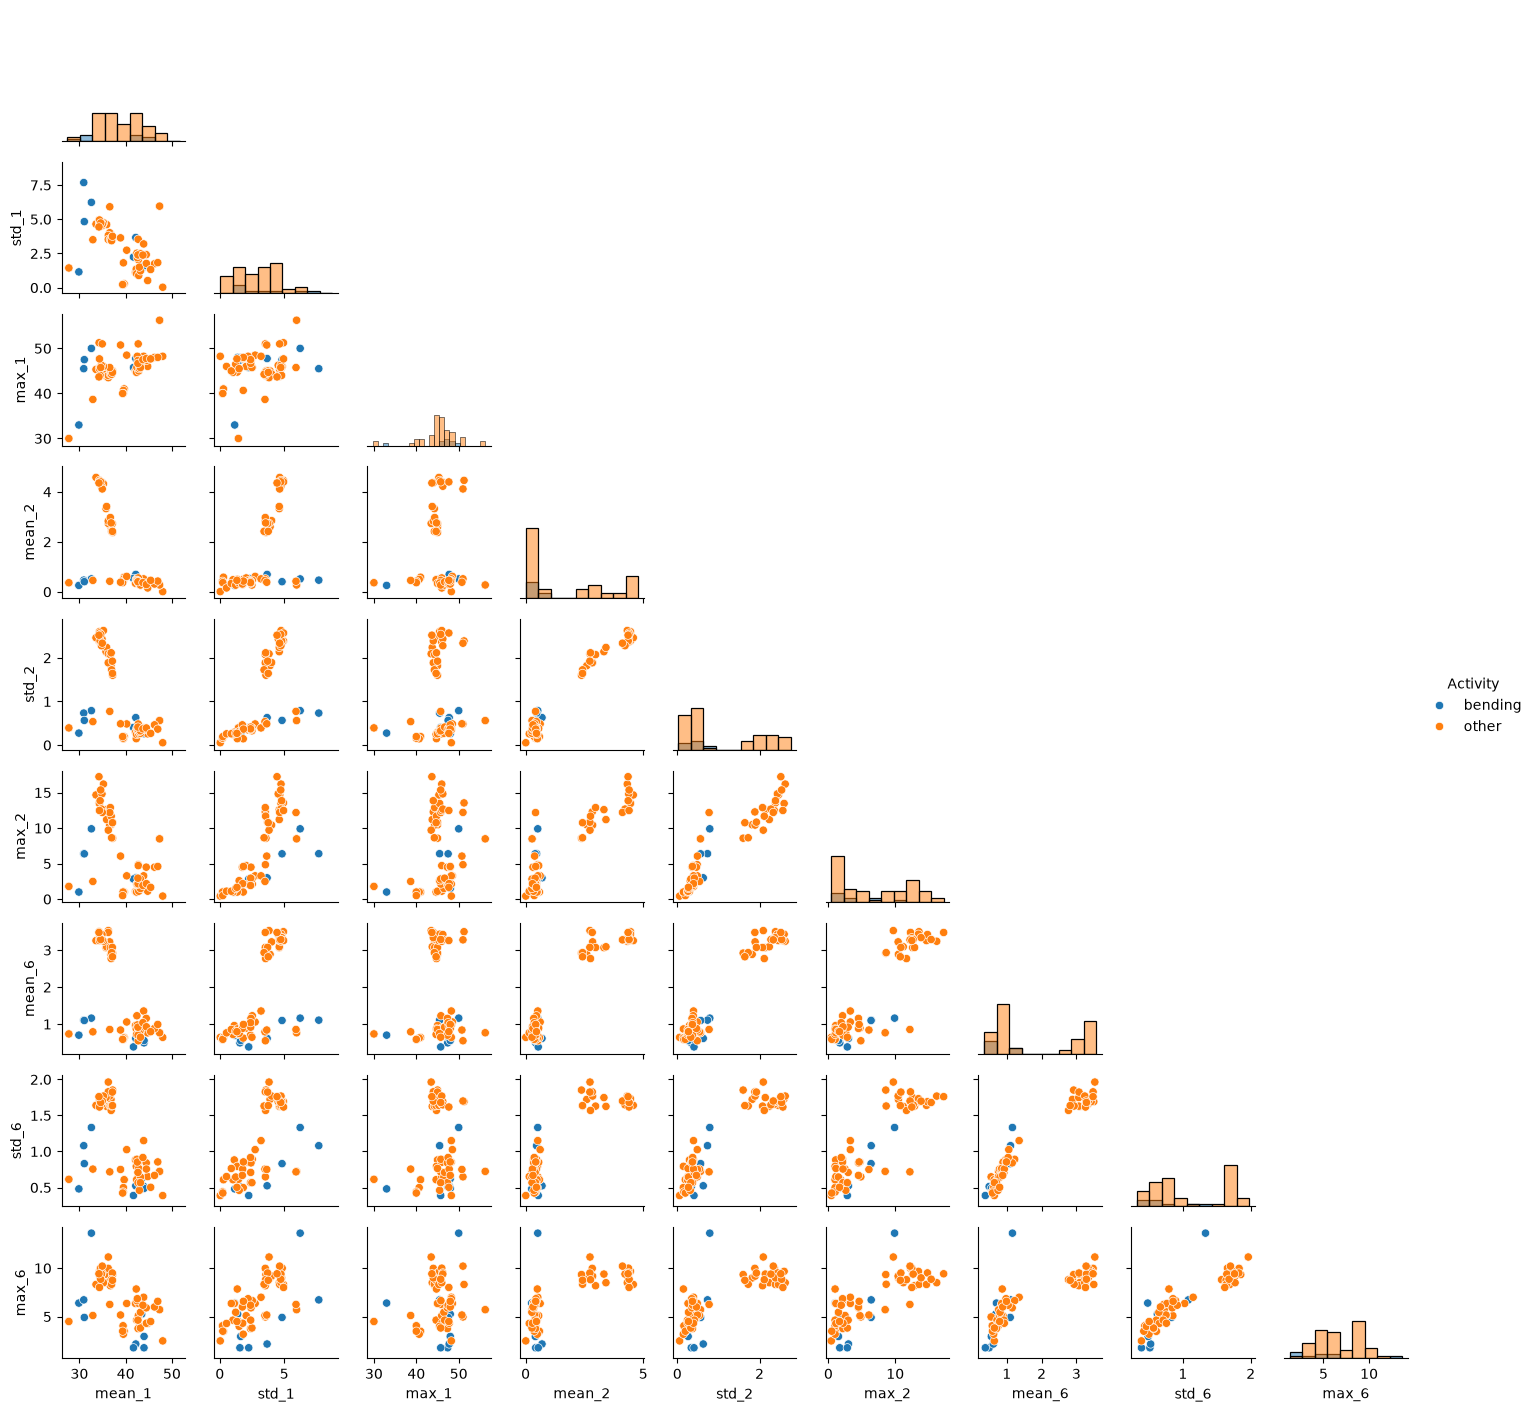

In [5]:
cols = [
    f"{s}_{i}"
    for i in [1, 2, 6]
    for s in ["mean", "std", "max"]
]

plot_data = features.loc[train_files, cols].copy()
plot_data["Activity"] = [
    "bending" if f.parent.name.startswith("bending") else "other"
    for f in plot_data.index
]

rows = []

for data in train_series:
    mid = len(data) // 2
    row = []
    for part in [data.iloc[:mid], data.iloc[mid:]]:
        row.extend(
            part[[1, 2, 6]].agg(["mean", "std", "max"]).T.to_numpy().ravel()
        )
    rows.append(row)

cols2 = [
    f"{s}_{i}_p{j}"
    for j in [1, 2]
    for i in [1, 2, 6]
    for s in ["mean", "std", "max"]
]

plot_data2 = pd.DataFrame(rows, columns=cols2, index=train_files)
plot_data2["Activity"] = plot_data["Activity"]

# Use the same bins and limits for each full-series and half-series feature.
plot_bins = {}
plot_limits = {}
for name in cols:
    values = np.r_[plot_data[name], plot_data2[name + "_p1"], plot_data2[name + "_p2"]]
    edges = np.histogram_bin_edges(values, bins="auto")
    plot_bins[name] = edges
    margin = 0.05 * (edges[-1] - edges[0])
    plot_limits[name] = (edges[0] - margin, edges[-1] + margin)

def shared_hist(x, color, **kwargs):
    sns.histplot(x, bins=plot_bins[x.name.split("_p")[0]], color=color, alpha=0.5, **kwargs)

def plot_features(data, columns, height):
    grid = sns.PairGrid(
        data, vars=columns, hue="Activity", hue_order=["bending", "other"],
        corner=True, height=height, diag_sharey=False
    )
    grid.map_lower(sns.scatterplot, edgecolor="white")
    grid.map_diag(shared_hist)
    grid.add_legend()
    for i, y in enumerate(columns):
        for j, x in enumerate(columns[:i + 1]):
            grid.axes[i, j].set_xlim(plot_limits[x.split("_p")[0]])
            if i != j:
                grid.axes[i, j].set_ylim(plot_limits[y.split("_p")[0]])
    for ax in grid.diag_axes:
        ax.set_ylim(0, plot_data["Activity"].value_counts().max())
    return grid

full_plot = plot_features(plot_data, cols, 1.6)
plt.show()

#### ii. Plots After Splitting


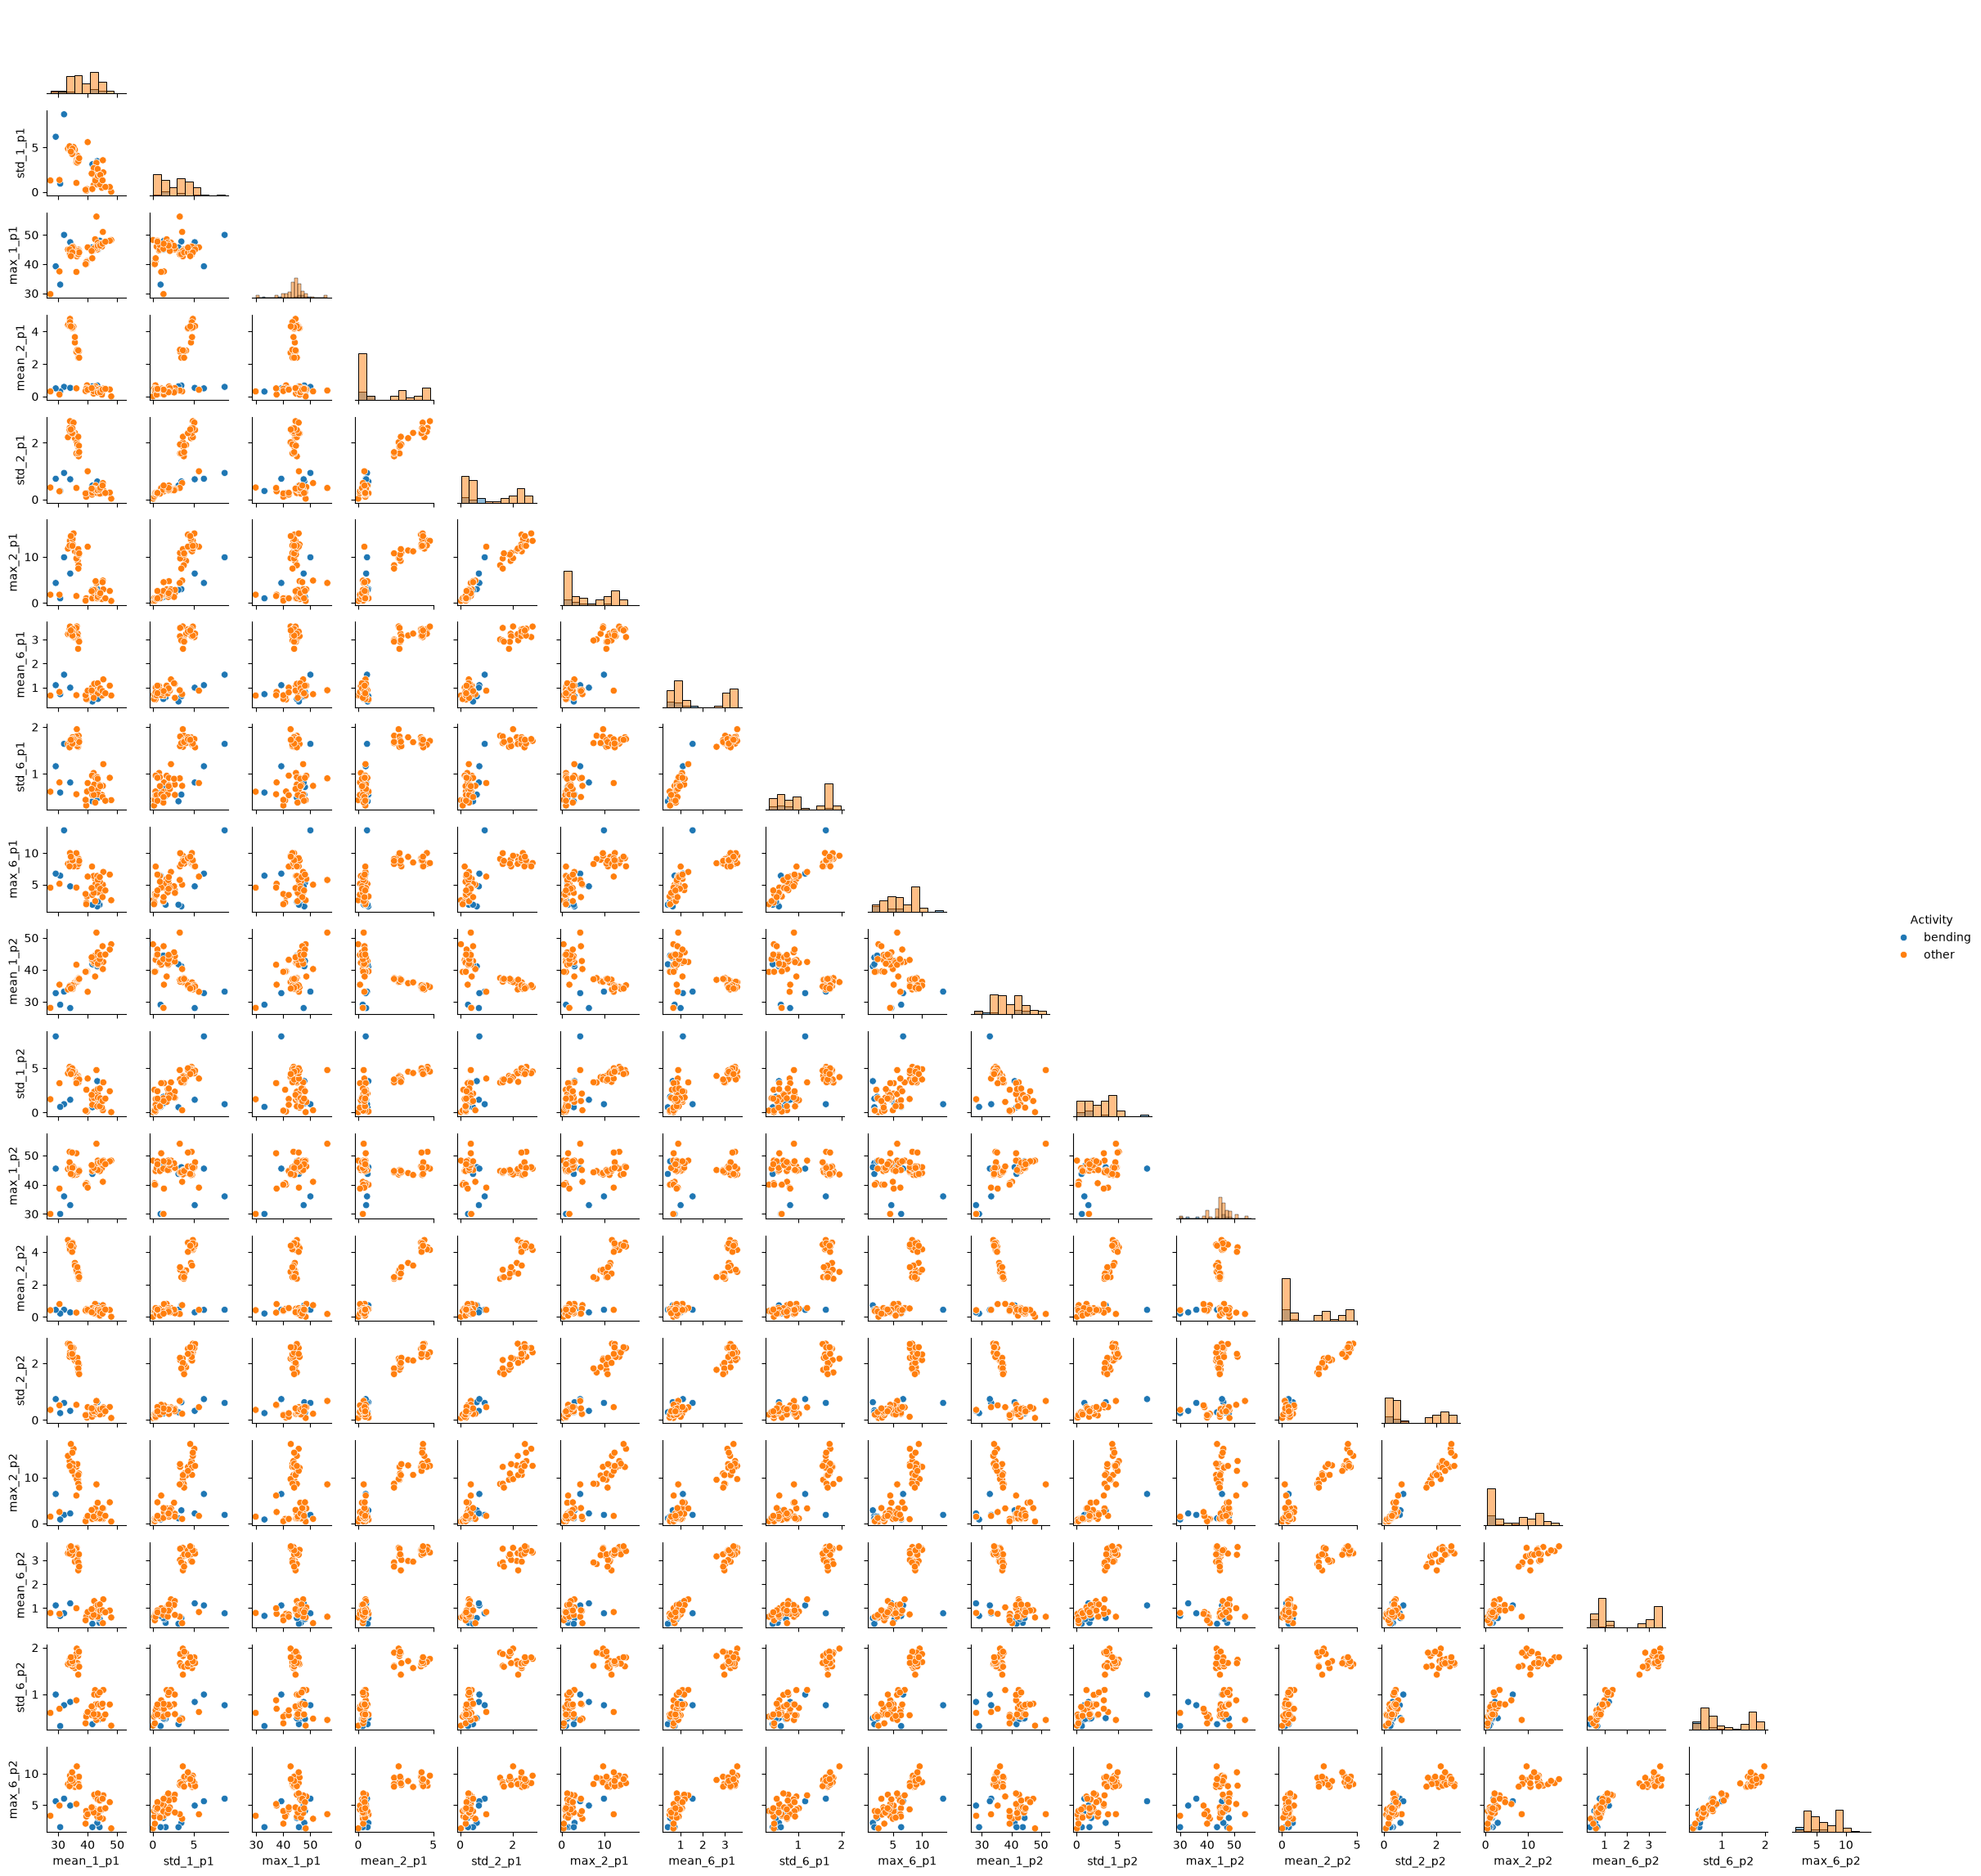

In [6]:
split_plot = plot_features(plot_data2, cols2, 1.3)
plt.show()

Splitting the series changes some feature values but gives no clear
overall improvement in class separation. Bending and other activities
still overlap in many plots.


#### iii. Time Series Segments

In [7]:
y_train = np.array([int(f.parent.name.startswith("bending")) for f in train_files])

# Cache each feature matrix so all models use the same values.
feature_cache = {
    ("train", 1): features.loc[train_files].reset_index(drop=True).add_suffix("_p1"),
    ("test", 1): features.loc[test_files].reset_index(drop=True).add_suffix("_p1")
}

def segment_features(l, split="train"):
    key = (split, l)
    if key in feature_cache:
        return feature_cache[key]
    rows = []
    for data in (train_series if split == "train" else test_series):
        row = []
        for idx in np.array_split(np.arange(len(data)), l):
            row.extend(data.iloc[idx].describe().loc[
                ["min", "max", "mean", "50%", "std", "25%", "75%"]
            ].T.to_numpy().ravel())
        rows.append(row)
    feature_cache[key] = pd.DataFrame(rows, columns=[
        f"{s}_{i}_p{j}"
        for j in range(1, l + 1)
        for i in range(1, 7)
        for s in ["min", "max", "mean", "median", "std", "q1", "q3"]
    ])
    return feature_cache[key]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, solver="liblinear", max_iter=2000, random_state=42)
)

results = []
best_score = -1

for l in range(1, 21):
    X = segment_features(l)
    selector = RFECV(
        model, step=1, cv=cv, scoring="accuracy",
        importance_getter="named_steps.logisticregression.coef_"
    ).fit(X, y_train)
    score = selector.cv_results_["mean_test_score"].max()
    results.append([l, selector.n_features_, score])
    if score > best_score:
        best_l, best_score = l, score
        best_model, best_X = selector, X

results = pd.DataFrame(results, columns=["l", "p", "CV accuracy"])
display(results)
print(f"Best: l={best_l}, p={best_model.n_features_}, CV accuracy={best_score:.4f}")
print("Selected features:", best_X.columns[best_model.support_].tolist())

,l,p,CV accuracy
0,1,3,1.000000
1,2,10,0.942857
2,3,7,0.942857
3,4,13,0.971429
4,5,5,0.942857
5,6,6,0.971429
6,7,8,0.957143
7,8,10,0.957143
8,9,8,0.957143
9,10,5,0.985714


Best: l=1, p=3, CV accuracy=1.0000
Selected features: ['min_5_p1', 'max_5_p1', 'mean_5_p1']


RFE and stratified 5-fold CV select l and p. There are 69 training
instances and 42l features per instance.

Fit the scaler, select features, and fit the model within each training
fold. Then score the validation fold. Doing these steps on all training
data before CV leaks validation information. Fixed statistics can be
computed separately for each instance before CV. The test set is not
used for selection.

Stratification keeps class proportions similar across folds. With
9 bending and 60 other instances, every validation fold has both classes.


#### iv. Confusion Matrix

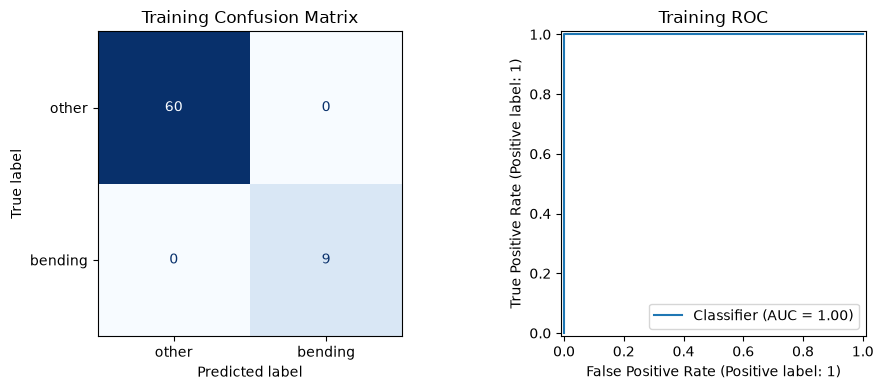

,Coefficient,Approx. Wald p-value
Intercept,-77.413098,0.708117
min_5_p1,92.414322,0.657208
max_5_p1,70.146644,0.655649
mean_5_p1,-49.026065,0.841133


In [8]:
pred_train = best_model.predict(best_X)
prob_train = best_model.predict_proba(best_X)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(
    y_train, pred_train, labels=[0, 1], display_labels=["other", "bending"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
RocCurveDisplay.from_predictions(y_train, prob_train, pos_label=1, ax=axes[1])
axes[0].set_title("Training Confusion Matrix")
axes[1].set_title("Training ROC")
plt.tight_layout()
plt.show()

pipe = best_model.estimator_
Z = pipe.named_steps["standardscaler"].transform(best_model.transform(best_X))
Z = np.column_stack([np.ones(len(Z)), Z])
lr = pipe.named_steps["logisticregression"]
beta = np.r_[lr.intercept_, lr.coef_.ravel()]

# These Wald values are unreliable under complete separation.
w = prob_train * (1 - prob_train)
se = np.sqrt(np.diag(np.linalg.inv(Z.T @ (w[:, None] * Z))))
params = pd.DataFrame(
    {"Coefficient": beta, "Approx. Wald p-value": 2 * norm.sf(np.abs(beta / se))},
    index=["Intercept"] + best_X.columns[best_model.support_].tolist()
)
display(params)

The training confusion matrix is [[60, 0], [0, 9]], with other = 0
and bending = 1. Training accuracy and AUC are both 1.000.

The coefficients use standardized features. The Wald p-values use the
observed information at the fitted coefficients. Complete separation
makes these p-values unreliable, as explained in 2(a)(vi). Large
p-values here do not mean that the features are unimportant.


#### v. Test Classifier

In [9]:
X_test = segment_features(best_l, "test")
y_test = np.array([int(f.parent.name.startswith("bending")) for f in test_files])
pred_test = best_model.predict(X_test)
test_accuracy = np.mean(pred_test == y_test)

print(f"CV accuracy: {best_score:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

CV accuracy: 1.0000
Test accuracy: 0.9474


The test set uses the same l = 1, selected features, and scaler fitted
on the training data. Test accuracy is 18/19 = 94.74%, compared with
100% in CV, a drop of about 5.26 percentage points.


#### vi. Separation

Yes. The selected features completely separate the training classes.
Training accuracy and AUC are both 1.000, and the coefficients are large.

With complete separation, unpenalized logistic regression has no finite
maximum likelihood estimate. Coefficients can grow without bound,
so Wald p-values are unreliable. Here, C = 1e6 adds a very weak L2
penalty and gives finite fitted coefficients.


#### vii. Imbalance

Intercept adjustment: -1.8971


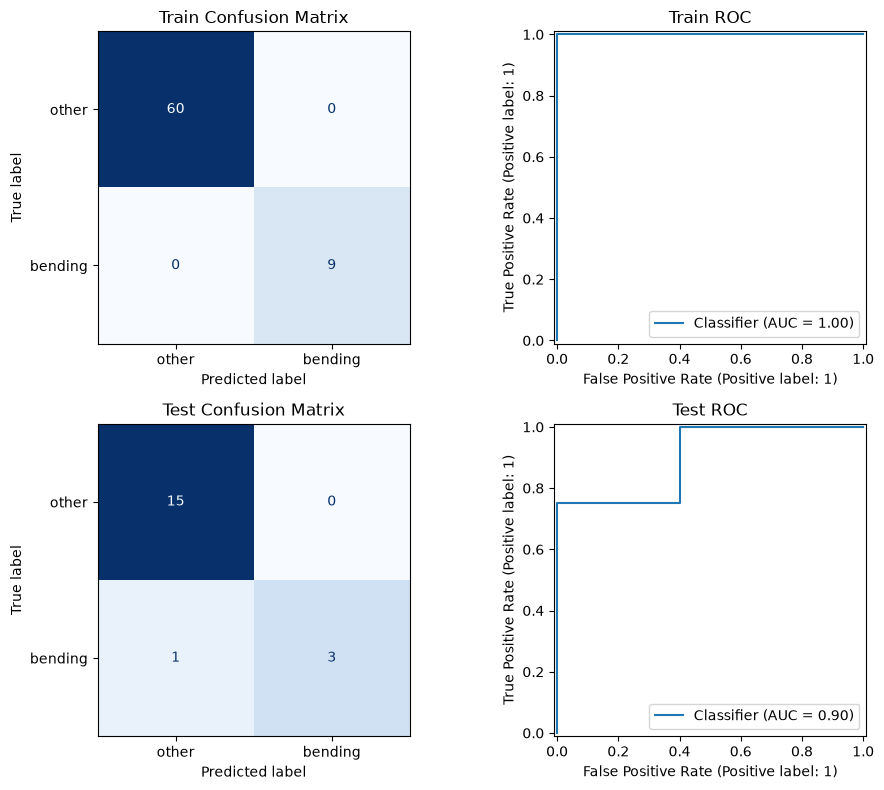

In [10]:
cases = np.flatnonzero(y_train == 1)
controls = np.flatnonzero(y_train == 0)
rng = np.random.default_rng(42)
sample_idx = np.r_[cases, rng.choice(controls, len(cases), replace=False)]

X_train_cc = best_model.transform(best_X)
X_test_cc = best_model.transform(X_test)
cc_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1e6, solver="liblinear", max_iter=2000, random_state=42)
)
cc_model.fit(X_train_cc[sample_idx], y_train[sample_idx])

# Correct the sampled prior using the original training case fraction.
pi = y_train.mean()
pi_sample = y_train[sample_idx].mean()
shift = np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
cc_model.named_steps["logisticregression"].intercept_ += shift
print(f"Intercept adjustment: {shift:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for row, (name, X, y) in enumerate([
    ("Train", X_train_cc, y_train),
    ("Test", X_test_cc, y_test)
]):
    pred = cc_model.predict(X)
    prob = cc_model.predict_proba(X)[:, 1]
    ConfusionMatrixDisplay.from_predictions(
        y, pred, labels=[0, 1], display_labels=["other", "bending"],
        cmap="Blues", colorbar=False, ax=axes[row, 0]
    )
    RocCurveDisplay.from_predictions(y, prob, pos_label=1, ax=axes[row, 1])
    axes[row, 0].set_title(f"{name} Confusion Matrix")
    axes[row, 1].set_title(f"{name} ROC")

plt.tight_layout()
plt.show()

The training set is imbalanced: 9 bending instances and 60 others.
I kept all 9 bending cases and sampled 9 controls without replacement.
The model uses the three features selected earlier.

I used the original training case fraction to estimate the target prior.
The intercept adjustment is logit(9/69) - logit(1/2) = -1.8971.

On the original training set, the confusion matrix is [[60, 0], [0, 9]]
and AUC is 1.000. On the test set, it is [[15, 0], [1, 3]] and AUC is
0.900. Test accuracy stays at 18/19 = 94.74%, so this sampling run
does not improve test accuracy.


### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
l1_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=2000, random_state=42)
)
l1_results = []
best_l1_score = -1

for l in range(1, 21):
    X = segment_features(l)
    search = GridSearchCV(
        l1_model, {"logisticregression__C": np.logspace(-4, 4, 9)},
        cv=cv, scoring="accuracy"
    ).fit(X, y_train)
    C = search.best_params_["logisticregression__C"]
    score = search.best_score_
    l1_results.append([l, C, score])
    if score > best_l1_score:
        best_l1_l, best_l1_C, best_l1_score = l, C, score
        best_l1_model, best_l1_X = search.best_estimator_, X

l1_results = pd.DataFrame(l1_results, columns=["l", "C", "CV accuracy"])
display(l1_results)

selected_l1 = best_l1_X.columns[
    best_l1_model.named_steps["logisticregression"].coef_[0] != 0
]
print(f"Best: l={best_l1_l}, C={best_l1_C:g}, CV accuracy={best_l1_score:.4f}")
print(f"Selected features ({len(selected_l1)}):", selected_l1.tolist())

,l,C,CV accuracy
0,1,10000.0,0.985714
1,2,10.0,0.971429
2,3,1.0,0.957143
3,4,1000.0,0.957143
4,5,100.0,0.941758
5,6,10.0,0.957143
6,7,100.0,0.956044
7,8,100.0,0.942857
8,9,10000.0,0.942857
9,10,100.0,0.971429


Best: l=1, C=10000, CV accuracy=0.9857
Selected features (36): ['min_1_p1', 'max_1_p1', 'mean_1_p1', 'median_1_p1', 'std_1_p1', 'q1_1_p1', 'q3_1_p1', 'max_2_p1', 'mean_2_p1', 'median_2_p1', 'std_2_p1', 'q3_2_p1', 'min_3_p1', 'max_3_p1', 'median_3_p1', 'std_3_p1', 'q1_3_p1', 'q3_3_p1', 'max_4_p1', 'mean_4_p1', 'median_4_p1', 'std_4_p1', 'q1_4_p1', 'min_5_p1', 'max_5_p1', 'mean_5_p1', 'median_5_p1', 'std_5_p1', 'q1_5_p1', 'min_6_p1', 'max_6_p1', 'mean_6_p1', 'median_6_p1', 'std_6_p1', 'q1_6_p1', 'q3_6_p1']


I used stratified 5-fold CV to search l = 1, ..., 20 and nine
logarithmically spaced C values from 0.0001 to 10000.

The best pair in this grid is l = 1 and C = 10000, with CV accuracy
of 98.57%. After fitting on all training data, 36 of 42 coefficients
are nonzero.

As in 2(a)(iii), scaling and feature selection stay within each training
fold. The test set is not used for selection.


#### ii. Comparison

Part (a) uses RFE, the allowed alternative to p-value-based selection.
RFE has higher CV accuracy than L1 here: 100% versus 98.57%.
It also keeps fewer features: 3 versus 36.

L1 is easier to implement than p-value-based selection. It selects
features during fitting, without separate p-value tests and pruning.


### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

c:\Users\a2785\Desktop\552\Homework\HW4\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,l,C,CV accuracy
0,1,1.0,0.884615
1,2,100.0,0.928571
2,3,1.0,0.827473
3,4,100.0,0.856044
4,5,100.0,0.870330
5,6,10.0,0.841758
6,7,100.0,0.827473
7,8,100.0,0.856044
8,9,100.0,0.841758
9,10,10.0,0.812088


Best: l=2, C=100, CV accuracy=0.9286
Test error: 0.1579


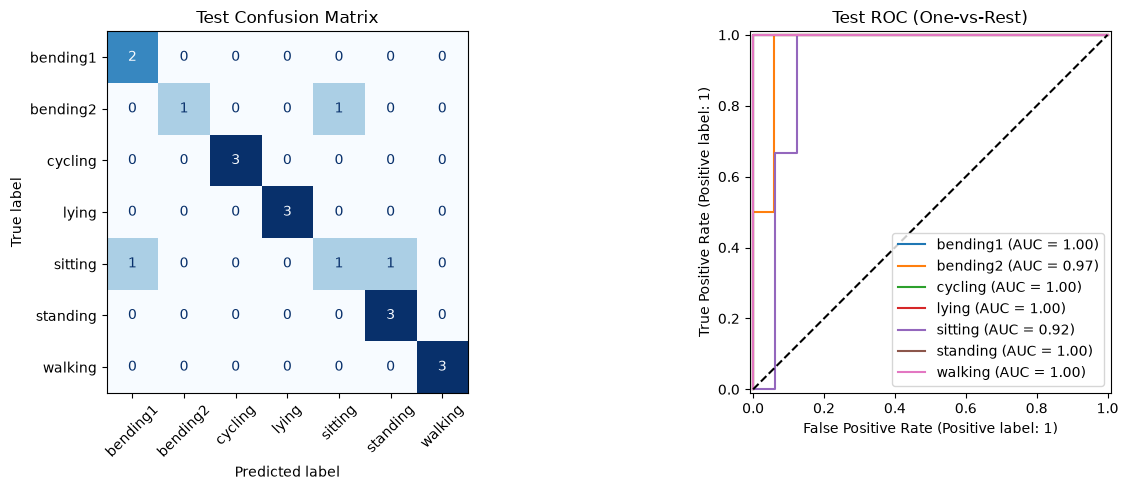

In [12]:
y_train_multi = np.array([f.parent.name for f in train_files])
y_test_multi = np.array([f.parent.name for f in test_files])
cv_multi = list(cv.split(train_series, y_train_multi))

multi_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        l1_ratio=1, solver="saga", max_iter=5000, tol=1e-3, random_state=42
    )
)
multi_results = []
best_multi_score = -1

for l in range(1, 21):
    X = segment_features(l)
    search = GridSearchCV(
        multi_model, {"logisticregression__C": np.logspace(-4, 4, 9)},
        cv=cv_multi, scoring="accuracy", n_jobs=4
    ).fit(X, y_train_multi)
    C = search.best_params_["logisticregression__C"]
    score = search.best_score_
    multi_results.append([l, C, score])
    if score > best_multi_score:
        best_multi_l, best_multi_C, best_multi_score = l, C, score
        best_multi_model = search.best_estimator_

multi_results = pd.DataFrame(multi_results, columns=["l", "C", "CV accuracy"])
display(multi_results)
print(f"Best: l={best_multi_l}, C={best_multi_C:g}, CV accuracy={best_multi_score:.4f}")

X_test_multi = segment_features(best_multi_l, "test")
pred_multi = best_multi_model.predict(X_test_multi)
prob_multi = best_multi_model.predict_proba(X_test_multi)
multi_test_error = np.mean(pred_multi != y_test_multi)
print(f"Test error: {multi_test_error:.4f}")

classes = best_multi_model.classes_
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_multi, pred_multi, labels=classes,
    cmap="Blues", colorbar=False, xticks_rotation=45, ax=axes[0]
)
axes[0].set_title("Test Confusion Matrix")

for i, label in enumerate(classes):
    RocCurveDisplay.from_predictions(
        y_test_multi == label, prob_multi[:, i], name=label, ax=axes[1]
    )
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Test ROC (One-vs-Rest)")
plt.tight_layout()
plt.show()

I used L1 multinomial logistic regression for all seven activities.
Stratified 5-fold CV uses the same l and C grid as 2(b)(i), with scaling
fitted within each training fold. The best pair is l = 2 and C = 100.
CV accuracy is 92.86%, and test error is 3/19 = 15.79%.

The 7 × 7 confusion matrix shows true classes in rows and predicted
classes in columns. Diagonal entries are correct predictions.
Each one-vs-rest ROC curve treats one activity as positive and all others
as negative. It shows the true positive rate against the false positive
rate as the probability threshold changes. The legend gives each AUC.

Bending2 has only four training instances, so one validation fold lacks
this class. All training folds still have seven classes, and validation
accuracy can still be calculated.


#### ii. Naive Bayes

Model,Gaussian NB,Multinomial NB
l,,
1,0.857143,0.854945
2,0.827473,0.795604
3,0.681319,0.796703
4,0.725275,0.782418
5,0.652747,0.812088
6,0.652747,0.783516
7,0.695604,0.783516
8,0.667033,0.782418
9,0.638462,0.783516


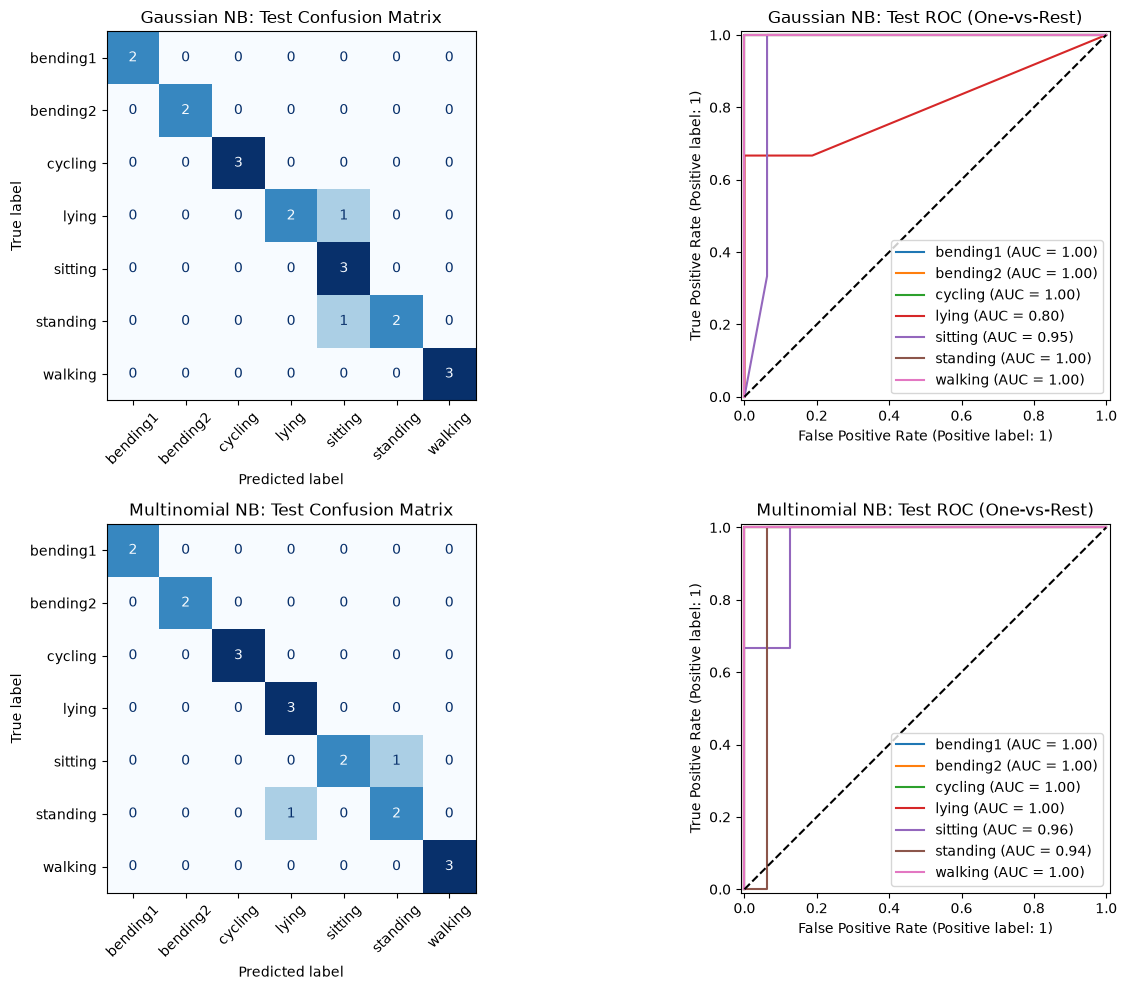

,Model,Best l,CV accuracy,Test error
0,Gaussian NB,1,0.857143,0.105263
1,Multinomial NB,1,0.854945,0.105263


In [13]:
nb_models = {"Gaussian NB": GaussianNB, "Multinomial NB": MultinomialNB}
nb_best = {}
nb_results = []

for l in range(1, 21):
    X = segment_features(l)
    for name, NB in nb_models.items():
        score = cross_val_score(
            NB(), X, y_train_multi, cv=cv_multi, scoring="accuracy"
        ).mean()
        nb_results.append([name, l, score])
        if name not in nb_best or score > nb_best[name]["score"]:
            nb_best[name] = {
                "l": l, "score": score, "model": NB().fit(X, y_train_multi)
            }

nb_results = pd.DataFrame(nb_results, columns=["Model", "l", "CV accuracy"])
display(nb_results.pivot(index="l", columns="Model", values="CV accuracy"))

nb_comparison = []
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, (name, best) in enumerate(nb_best.items()):
    model = best["model"]
    X_test_nb = segment_features(best["l"], "test")
    pred = model.predict(X_test_nb)
    prob = model.predict_proba(X_test_nb)
    error = np.mean(pred != y_test_multi)
    nb_comparison.append([name, best["l"], best["score"], error])

    ConfusionMatrixDisplay.from_predictions(
        y_test_multi, pred, labels=model.classes_, cmap="Blues",
        colorbar=False, xticks_rotation=45, ax=axes[row, 0]
    )
    axes[row, 0].set_title(f"{name}: Test Confusion Matrix")

    for i, label in enumerate(model.classes_):
        RocCurveDisplay.from_predictions(
            y_test_multi == label, prob[:, i], name=label, ax=axes[row, 1]
        )
    axes[row, 1].plot([0, 1], [0, 1], "k--")
    axes[row, 1].set_title(f"{name}: Test ROC (One-vs-Rest)")

plt.tight_layout()
plt.show()

nb_comparison = pd.DataFrame(
    nb_comparison, columns=["Model", "Best l", "CV accuracy", "Test error"]
)
display(nb_comparison)

Both NB models use the same five folds as 2(c)(i) to select l.
Other parameters stay at their defaults. Features are nonnegative
and are not standardized.

Both select l = 1. Gaussian NB has slightly higher CV accuracy:
85.71% versus 85.49%. Both make 2 errors out of 19 test instances,
so test error is 10.53%. Their wrong predictions differ. The
one-vs-rest ROC curves show each class's AUC.

Gaussian NB assumes Gaussian class-conditional feature distributions.
Multinomial NB normally uses counts, so using continuous nonnegative
statistics here is an approximation.


#### iii. Comparison

The two NB models tie for the lowest test error: 10.53% (2/19),
compared with 15.79% (3/19) for L1 multinomial logistic regression.

L1 has the highest CV accuracy: 92.86%, compared with 85.71% for
Gaussian NB and 85.49% for Multinomial NB. The test difference is
only one instance, so it does not show that NB is generally better.


## 3. ISLR 4.8.3

Let $\pi_k=P(Y=k)$. By Bayes' theorem, the classifier assigns $x$
to the class maximizing $\pi_k f_k(x)$, where

$$
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking logarithms and dropping terms common to all classes gives
the discriminant function

$$
\begin{aligned}
\delta_k(x)
&=\log\pi_k-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}\\
&=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac12\log\sigma_k^2+\log\pi_k.
\end{aligned}
$$

The decision boundary between classes $k$ and $j$ satisfies
$\delta_k(x)-\delta_j(x)=0$. Its coefficient of $x^2$ is

$$
\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2},
$$

which is nonzero when the two variances differ. Therefore, the
boundary equation is generally quadratic in $x$, giving QDA.

If all class variances are equal, the quadratic terms cancel when
comparing classes, and the rule reduces to the linear LDA rule.

## 4. ISLR 4.8.7

Let $Y=\text{Yes}$ denote issuing a dividend. The class priors are
$P(Y=\text{Yes})=0.8$ and $P(Y=\text{No})=0.2$, with

$$
X\mid Y=\text{Yes}\sim N(10,36),\qquad
X\mid Y=\text{No}\sim N(0,36).
$$

By Bayes' theorem,

$$
P(Y=\text{Yes}\mid X=4)
=\frac{0.8f_{\text{Yes}}(4)}
{0.8f_{\text{Yes}}(4)+0.2f_{\text{No}}(4)}.
$$

The normal densities have the same variance, so their common
normalizing constant cancels. Therefore,

$$
\begin{aligned}
P(Y=\text{Yes}\mid X=4)
&=\frac{0.8e^{-(4-10)^2/(2\cdot36)}}
{0.8e^{-(4-10)^2/(2\cdot36)}
+0.2e^{-(4-0)^2/(2\cdot36)}}\\
&=\frac{0.8e^{-1/2}}
{0.8e^{-1/2}+0.2e^{-2/9}}\\
&\approx 0.7519.
\end{aligned}
$$

Thus, the estimated probability that the company issues a dividend
is approximately **75.19%**.

## 5.1. Extra Practice ISLR 4.8.4

Under the uniform unit-hypercube model, ignoring boundary effects,
the expected fraction of observations in a region equals its volume.

**(a)** For $p=1$, the interval has length $0.1$, so we use
$0.1=10\%$ of the observations.

**(b)** For $p=2$, the region has area
$0.1\times0.1=0.01$, so we use $1\%$ of the observations.

**(c)** For $p=100$, the fraction is

$$
(0.1)^{100}=10^{-100},
$$

which is effectively zero for any practical sample size.

**(d)** The fraction of observations in a fixed local neighborhood
decreases exponentially with the number of dimensions. Consequently,
very few training observations are close to a test observation in
high dimensions, making local methods such as KNN less effective.

**(e)** Let $s$ be the side length of the hypercube. To contain an
expected fraction of $0.1$ of the observations, we need

$$
s^p=0.1
\quad\Longrightarrow\quad
s=0.1^{1/p}.
$$

For $p=1$, $s=0.1$.

For $p=2$, $s=\sqrt{0.1}\approx0.3162$.

For $p=100$, $s=0.1^{1/100}\approx0.9772$.

Thus, in 100 dimensions, each side must span approximately 97.72%
of the feature's range to include just 10% of the observations.
The neighborhood is therefore no longer very local.

## 5.2. Extra Practice ISLR 4.8.9

Let $p$ denote the probability of default. The odds of default are
$p/(1-p)$.

**(a)** Given odds of $0.37$,

$$
\frac{p}{1-p}=0.37
\quad\Longrightarrow\quad
p=\frac{0.37}{1+0.37}\approx0.2701.
$$

Therefore, approximately **27.01%** of these people will default.

**(b)** Given $p=0.16$,

$$
\text{odds}=\frac{0.16}{1-0.16}
=\frac{0.16}{0.84}
=\frac{4}{21}\approx0.1905.
$$

Thus, the odds of default are approximately **0.1905**, or **4:21**.